In [1]:
%pip install pandas openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd

df = pd.read_excel("Resume/Resume.xlsx")

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Resume/Resume.xlsx'

In [2]:
import os

os.listdir("Resume")

['Resume.csv']

In [3]:
import pandas as pd

df = pd.read_csv("Resume/Resume.csv")

df.head()

,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [4]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Shape: (2484, 4)

Columns:
['ID', 'Resume_str', 'Resume_html', 'Category']

Data Types:
ID             int64
Resume_str       str
Resume_html      str
Category         str
dtype: object


In [5]:
df.isnull().sum()

ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["Category"].value_counts()

Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
FINANCE                   118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
AVIATION                  117
SALES                     116
HEALTHCARE                115
CONSULTANT                115
BANKING                   115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64

In [8]:
df["Resume_str"].str.len().describe()

count     2484.000000
mean      6295.308776
std       2769.251458
min         21.000000
25%       5160.000000
50%       5886.500000
75%       7227.250000
max      38842.000000
Name: Resume_str, dtype: float64

In [9]:
(df["Resume_str"].str.strip() == "").sum()

np.int64(1)

In [10]:
import re

# Blank resume remove
df = df[df["Resume_str"].str.strip() != ""].copy()

# Resume text cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df["Resume_clean"] = df["Resume_str"].apply(clean_text)

df[["Resume_str", "Resume_clean", "Category"]].head()

,Resume_str,Resume_clean,Category
0,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,hr administrator marketing associate hr admini...,HR
1,"HR SPECIALIST, US HR OPERATIONS ...",hr specialist us hr operations summary versati...,HR
2,HR DIRECTOR Summary Over 2...,hr director summary over years experience in r...,HR
3,HR SPECIALIST Summary Dedica...,hr specialist summary dedicated driven and dyn...,HR
4,HR MANAGER Skill Highlights ...,hr manager skill highlights hr skills hr depar...,HR


In [11]:
df = df.drop(columns=["Resume_html"])

In [12]:
df.head()

,ID,Resume_str,Category,Resume_clean
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,HR,hr administrator marketing associate hr admini...
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...",HR,hr specialist us hr operations summary versati...
2,33176873,HR DIRECTOR Summary Over 2...,HR,hr director summary over years experience in r...
3,27018550,HR SPECIALIST Summary Dedica...,HR,hr specialist summary dedicated driven and dyn...
4,17812897,HR MANAGER Skill Highlights ...,HR,hr manager skill highlights hr skills hr depar...


In [13]:
%pip install nltk

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------- ----- 1.6/1.8 MB 8.0 MB/s eta 0:00:01
   ---------------------------------------- 1.8/1.8 MB 7.2 MB/s  0:00:00

   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ------------- -------------------------- 1/3 [regex]
   ------------- -------------------------- 1/3 [regex]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   ------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import nltk
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to C:\Users\AKHILESH KR
[nltk_data]     GAUTAM.AKHILESH\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [15]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def remove_stopwords(text):
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df["Resume_clean"] = df["Resume_clean"].apply(remove_stopwords)

In [16]:
df[["Resume_clean", "Category"]].head()

,Resume_clean,Category
0,hr administrator marketing associate hr admini...,HR
1,hr specialist us hr operations summary versati...,HR
2,hr director summary years experience recruitin...,HR
3,hr specialist summary dedicated driven dynamic...,HR
4,hr manager skill highlights hr skills hr depar...,HR


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X = tfidf.fit_transform(df["Resume_clean"])

print("TF-IDF Shape:", X.shape)

TF-IDF Shape: (2483, 5000)


In [18]:
y = df["Category"]

print("Target Shape:", y.shape)
print("Number of Categories:", y.nunique()

_IncompleteInputError: incomplete input (527892190.py, line 4)

In [19]:
y = df["Category"]

print("Target Shape:", y.shape)
print("Number of Categories:", y.nunique())

Target Shape: (2483,)
Number of Categories: 24


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1986, 5000)
Testing data: (497, 5000)


In [21]:
from sklearn.svm import LinearSVC

model = LinearSVC()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [22]:
y_pred = model.predict(X_test)

print(y_pred[:10])

['DESIGNER' 'DIGITAL-MEDIA' 'CONSTRUCTION' 'HEALTHCARE' 'CONSTRUCTION'
 'HR' 'AUTOMOBILE' 'DIGITAL-MEDIA' 'DIGITAL-MEDIA' 'DIGITAL-MEDIA']


In [23]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.7364185110663984


In [24]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                        precision    recall  f1-score   support

            ACCOUNTANT       0.70      0.88      0.78        24
              ADVOCATE       0.64      0.75      0.69        24
           AGRICULTURE       1.00      0.62      0.76        13
               APPAREL       0.58      0.37      0.45        19
                  ARTS       0.60      0.43      0.50        21
            AUTOMOBILE       0.75      0.43      0.55         7
              AVIATION       0.86      0.75      0.80        24
               BANKING       0.74      0.74      0.74        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.67      0.83      0.74        24
                  CHEF       0.86      0.75      0.80        24
          CONSTRUCTION       0.79      0.86      0.83        22
            CONSULTANT       0.75      0.52      0.62        23
              DESIGNER       0.87      0.95      0.91        21
         DIGITAL-MEDIA       0.75      

In [25]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(14, 10))
sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Resume Category Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

ModuleNotFoundError: No module named 'matplotlib'

In [26]:
%pip install matplotlib seaborn

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ----------- ---------------------------- 2.6/9.3 MB 14.3 MB/s eta 0:00:01
   ------------------------------ --------- 7.1/9.3 MB 17.3 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 16.4 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 20.6 MB/s  0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ------------------------------ --------- 5.5/7.2 MB 26.2 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 21.9 MB/s  0:00:00

   ---------------------------------------- 0/8 [pyparsing]
   ---------------------------------------- 0/8 [pyparsing]
   ---------------------------------------- 0/8 [pyparsing]
   ----- ---------------------------------- 1/8 [pillow]
   ----- ---------------------------------- 1/8 [pillow]
   ----- ---------------------------------- 1


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


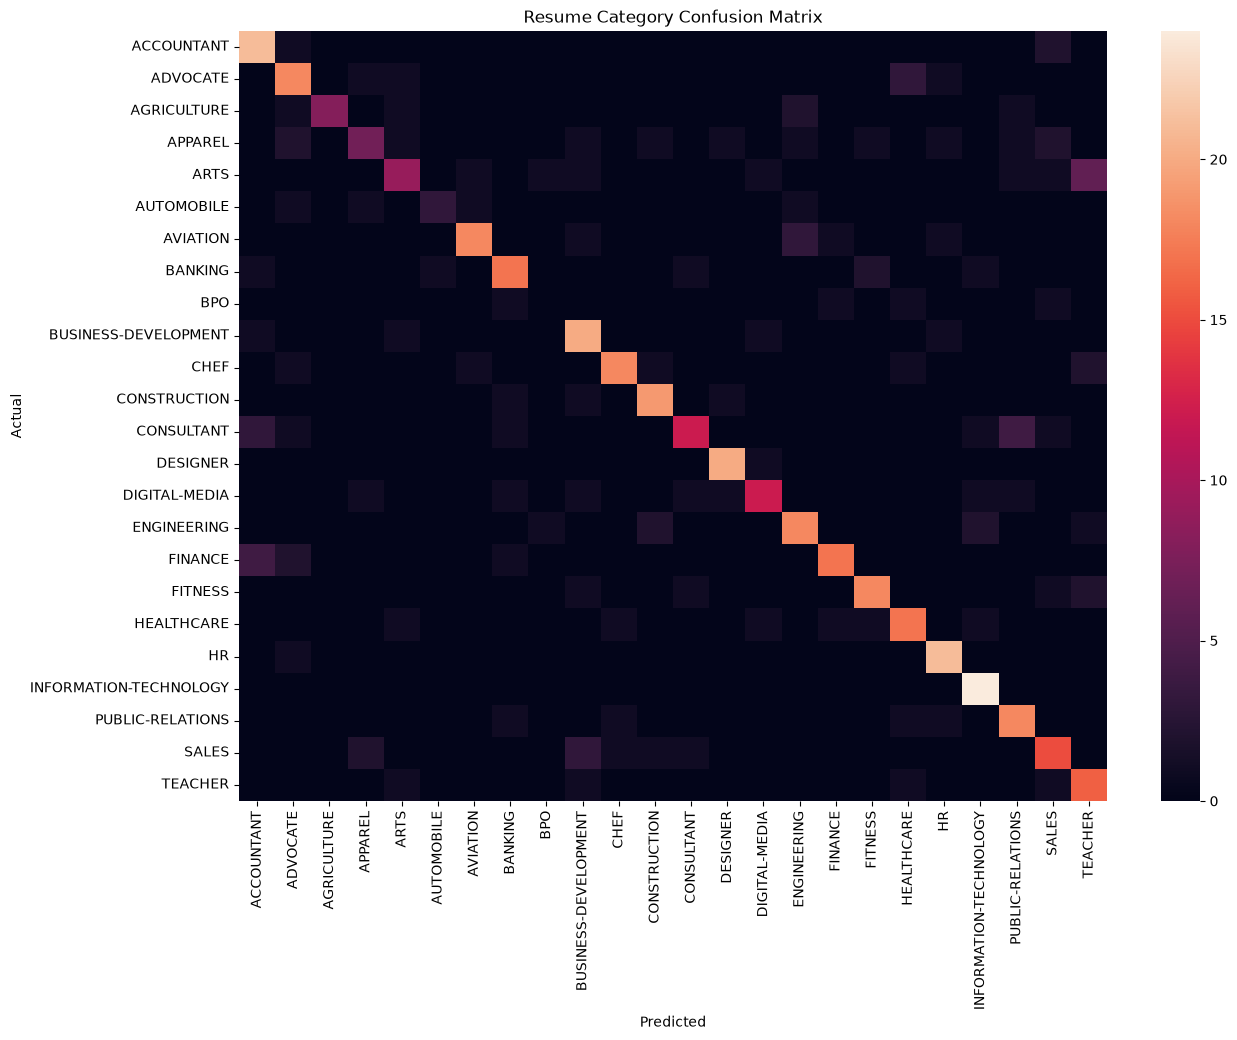

In [27]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=False,
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Resume Category Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

In [28]:
job_description = """
We are looking for a Python Developer with strong skills in
Python, Django, Flask, SQL, REST API, Git, data structures,
and software development.
"""

In [29]:
job_clean = clean_text(job_description)

job_clean = remove_stopwords(job_clean)

print(job_clean)

looking python developer strong skills python django flask sql rest api git data structures software development


In [30]:
job_vector = tfidf.transform([job_clean])

In [31]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_scores = cosine_similarity(job_vector, X).flatten()

print(similarity_scores[:10])

[0.00775819 0.00613538 0.01282348 0.00296107 0.01522926 0.00428527
 0.01841761 0.01098038 0.01041303 0.01297579]


In [32]:
df["Match_Score"] = similarity_scores * 100

In [33]:
ranked_candidates = df.sort_values(
    by="Match_Score",
    ascending=False
)

ranked_candidates[
    ["ID", "Category", "Match_Score"]
].head(10)

,ID,Category,Match_Score
926,62994611,AGRICULTURE,27.930309
1218,21156767,CONSULTANT,21.323614
1756,32985311,ENGINEERING,19.954747
1799,10624813,ENGINEERING,19.378549
2395,12144825,AVIATION,19.022844
1742,51588273,ENGINEERING,19.012891
1762,12011623,ENGINEERING,17.670527
1303,42156237,DIGITAL-MEDIA,17.613278
1339,18448085,AUTOMOBILE,17.520655
1142,30863060,CONSULTANT,16.816062


In [34]:
shortlisted = ranked_candidates[
    ranked_candidates["Match_Score"] >= 60
]

print("Shortlisted Candidates:", len(shortlisted))

shortlisted[
    ["ID", "Category", "Match_Score"]
].head(20)

Shortlisted Candidates: 0


,ID,Category,Match_Score


In [35]:
shortlisted = ranked_candidates[
    ranked_candidates["Match_Score"] >= 15
]

print("Shortlisted Candidates:", len(shortlisted))

shortlisted[
    ["ID", "Category", "Match_Score"]
].head(20)

Shortlisted Candidates: 16


,ID,Category,Match_Score
926,62994611,AGRICULTURE,27.930309
1218,21156767,CONSULTANT,21.323614
1756,32985311,ENGINEERING,19.954747
1799,10624813,ENGINEERING,19.378549
2395,12144825,AVIATION,19.022844
1742,51588273,ENGINEERING,19.012891
1762,12011623,ENGINEERING,17.670527
1303,42156237,DIGITAL-MEDIA,17.613278
1339,18448085,AUTOMOBILE,17.520655
1142,30863060,CONSULTANT,16.816062


In [36]:
required_skills = [
    "python",
    "django",
    "flask",
    "sql",
    "rest api",
    "git",
    "data structures",
    "software development"
]

print("Required Skills:")
print(required_skills)

Required Skills:
['python', 'django', 'flask', 'sql', 'rest api', 'git', 'data structures', 'software development']


In [37]:
def skill_match_score(resume, skills):
    resume = resume.lower()
    matched = [skill for skill in skills if skill in resume]
    
    score = (len(matched) / len(skills)) * 100
    
    return score, matched

results = []

for _, row in df.iterrows():
    score, matched = skill_match_score(
        row["Resume_clean"],
        required_skills
    )
    
    results.append({
        "ID": row["ID"],
        "Category": row["Category"],
        "Skill_Score": score,
        "Matched_Skills": ", ".join(matched)
    })

skill_df = pd.DataFrame(results)

skill_df = skill_df.sort_values(
    by="Skill_Score",
    ascending=False
)

skill_df.head(20)

,ID,Category,Skill_Score,Matched_Skills
1798,10624813,ENGINEERING,50.0,"python, sql, git, software development"
2394,12144825,AVIATION,50.0,"python, sql, git, software development"
2456,23464505,AVIATION,50.0,"sql, git, data structures, software development"
267,13405733,INFORMATION-TECHNOLOGY,50.0,"python, sql, git, software development"
1151,39441617,CONSULTANT,50.0,"python, sql, git, software development"
1110,43311839,CONSULTANT,50.0,"sql, rest api, git, software development"
925,62994611,AGRICULTURE,50.0,"python, flask, sql, software development"
1793,26456899,ENGINEERING,37.5,"sql, git, software development"
1749,27152464,ENGINEERING,37.5,"python, sql, git"
2198,21297521,BANKING,37.5,"sql, git, software development"


In [38]:
final_df = ranked_candidates.merge(
    skill_df,
    on=["ID", "Category"]
)

final_df["ATS_Score"] = (
    final_df["Match_Score"] * 0.4 +
    final_df["Skill_Score"] * 0.6
)

final_df = final_df.sort_values(
    by="ATS_Score",
    ascending=False
)

final_df[
    ["ID", "Category", "Match_Score",
     "Skill_Score", "ATS_Score", "Matched_Skills"]
].head(20)

,ID,Category,Match_Score,Skill_Score,ATS_Score,Matched_Skills
0,62994611,AGRICULTURE,27.930309,50.0,41.172124,"python, flask, sql, software development"
3,10624813,ENGINEERING,19.378549,50.0,37.751420,"python, sql, git, software development"
4,12144825,AVIATION,19.022844,50.0,37.609138,"python, sql, git, software development"
20,43311839,CONSULTANT,13.821580,50.0,35.528632,"sql, rest api, git, software development"
30,13405733,INFORMATION-TECHNOLOGY,11.995800,50.0,34.798320,"python, sql, git, software development"
54,39441617,CONSULTANT,8.816338,50.0,33.526535,"python, sql, git, software development"
60,23464505,AVIATION,8.393951,50.0,33.357581,"sql, git, data structures, software development"
1,21156767,CONSULTANT,21.323614,37.5,31.029446,"python, sql, software development"
7,42156237,DIGITAL-MEDIA,17.613278,37.5,29.545311,"python, sql, git"
10,27152464,ENGINEERING,16.116324,37.5,28.946529,"python, sql, git"


In [39]:
shortlisted = final_df[
    final_df["ATS_Score"] >= 30
].copy()

print("Shortlisted Candidates:", len(shortlisted))

shortlisted[
    ["ID", "Category", "Match_Score",
     "Skill_Score", "ATS_Score", "Matched_Skills"]
].head(20)

Shortlisted Candidates: 8


,ID,Category,Match_Score,Skill_Score,ATS_Score,Matched_Skills
0,62994611,AGRICULTURE,27.930309,50.0,41.172124,"python, flask, sql, software development"
3,10624813,ENGINEERING,19.378549,50.0,37.751420,"python, sql, git, software development"
4,12144825,AVIATION,19.022844,50.0,37.609138,"python, sql, git, software development"
20,43311839,CONSULTANT,13.821580,50.0,35.528632,"sql, rest api, git, software development"
30,13405733,INFORMATION-TECHNOLOGY,11.995800,50.0,34.798320,"python, sql, git, software development"
54,39441617,CONSULTANT,8.816338,50.0,33.526535,"python, sql, git, software development"
60,23464505,AVIATION,8.393951,50.0,33.357581,"sql, git, data structures, software development"
1,21156767,CONSULTANT,21.323614,37.5,31.029446,"python, sql, software development"


In [40]:
top_candidates = final_df.head(10).copy()

top_candidates[
    ["ID", "Category", "Match_Score",
     "Skill_Score", "ATS_Score", "Matched_Skills"]
]

,ID,Category,Match_Score,Skill_Score,ATS_Score,Matched_Skills
0,62994611,AGRICULTURE,27.930309,50.0,41.172124,"python, flask, sql, software development"
3,10624813,ENGINEERING,19.378549,50.0,37.751420,"python, sql, git, software development"
4,12144825,AVIATION,19.022844,50.0,37.609138,"python, sql, git, software development"
20,43311839,CONSULTANT,13.821580,50.0,35.528632,"sql, rest api, git, software development"
30,13405733,INFORMATION-TECHNOLOGY,11.995800,50.0,34.798320,"python, sql, git, software development"
54,39441617,CONSULTANT,8.816338,50.0,33.526535,"python, sql, git, software development"
60,23464505,AVIATION,8.393951,50.0,33.357581,"sql, git, data structures, software development"
1,21156767,CONSULTANT,21.323614,37.5,31.029446,"python, sql, software development"
7,42156237,DIGITAL-MEDIA,17.613278,37.5,29.545311,"python, sql, git"
10,27152464,ENGINEERING,16.116324,37.5,28.946529,"python, sql, git"


In [41]:
def recommendation(score):
    if score >= 40:
        return "Strong Match"
    elif score >= 30:
        return "Good Match"
    elif score >= 20:
        return "Moderate Match"
    else:
        return "Low Match"

final_df["Recommendation"] = final_df["ATS_Score"].apply(recommendation)

final_df[
    ["ID", "Category", "ATS_Score",
     "Recommendation", "Matched_Skills"]
].head(20)

,ID,Category,ATS_Score,Recommendation,Matched_Skills
0,62994611,AGRICULTURE,41.172124,Strong Match,"python, flask, sql, software development"
3,10624813,ENGINEERING,37.751420,Good Match,"python, sql, git, software development"
4,12144825,AVIATION,37.609138,Good Match,"python, sql, git, software development"
20,43311839,CONSULTANT,35.528632,Good Match,"sql, rest api, git, software development"
30,13405733,INFORMATION-TECHNOLOGY,34.798320,Good Match,"python, sql, git, software development"
54,39441617,CONSULTANT,33.526535,Good Match,"python, sql, git, software development"
60,23464505,AVIATION,33.357581,Good Match,"sql, git, data structures, software development"
1,21156767,CONSULTANT,31.029446,Good Match,"python, sql, software development"
7,42156237,DIGITAL-MEDIA,29.545311,Moderate Match,"python, sql, git"
10,27152464,ENGINEERING,28.946529,Moderate Match,"python, sql, git"


In [42]:
import joblib

joblib.dump(model, "resume_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [43]:
joblib.dump(required_skills, "required_skills.pkl")

print("Skills list saved!")

Skills list saved!


In [1]:
print("Model:", model)
print("Vectorizer:", tfidf)
print("Required Skills:", required_skills)

print("\nProject setup completed successfully!")

NameError: name 'model' is not defined

In [2]:
print("Model:", model)

NameError: name 'model' is not defined

In [3]:
import joblib

model = joblib.load("resume_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")
required_skills = joblib.load("required_skills.pkl")

print("Model loaded:", type(model))
print("Vectorizer loaded:", type(tfidf))
print("Required Skills:", required_skills)

Model loaded: <class 'sklearn.svm._classes.LinearSVC'>
Vectorizer loaded: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>
Required Skills: ['python', 'django', 'flask', 'sql', 'rest api', 'git', 'data structures', 'software development']


In [4]:
# Test Resume Screening

resume_text = """
Python developer with experience in Python, Django, Flask,
SQL, REST API, Git, data structures and software development.
"""

# Clean resume
resume_clean = clean_text(resume_text)
resume_clean = remove_stopwords(resume_clean)

# Convert resume into TF-IDF
resume_vector = tfidf.transform([resume_clean])

# Predict category
predicted_category = model.predict(resume_vector)[0]

print("Predicted Resume Category:", predicted_category)

NameError: name 'clean_text' is not defined

In [5]:
import joblib

model = joblib.load("resume_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")
required_skills = joblib.load("required_skills.pkl")

print("Model loaded:", type(model))
print("Vectorizer loaded:", type(tfidf))
print("Skills loaded:", required_skills)

Model loaded: <class 'sklearn.svm._classes.LinearSVC'>
Vectorizer loaded: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>
Skills loaded: ['python', 'django', 'flask', 'sql', 'rest api', 'git', 'data structures', 'software development']


In [6]:
import re
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def remove_stopwords(text):
    words = text.split()
    return " ".join(
        word for word in words
        if word not in stop_words
    )

print("Cleaning functions ready!")

Cleaning functions ready!


In [7]:
resume_text = """
Python developer with experience in Python, Django, Flask,
SQL, REST API, Git, data structures and software development.
"""

resume_clean = clean_text(resume_text)
resume_clean = remove_stopwords(resume_clean)

resume_vector = tfidf.transform([resume_clean])

predicted_category = model.predict(resume_vector)[0]

print("Predicted Resume Category:", predicted_category)

Predicted Resume Category: ENGINEERING


In [8]:
from sklearn.metrics.pairwise import cosine_similarity

# Job Description
job_description = """
We are looking for a Python Developer with strong skills in
Python, Django, Flask, SQL, REST API, Git, Data Structures
and Software Development.
"""

# Clean job description
job_clean = clean_text(job_description)
job_clean = remove_stopwords(job_clean)

# Convert both texts to TF-IDF
job_vector = tfidf.transform([job_clean])
resume_vector = tfidf.transform([resume_clean])

# Similarity score
similarity_score = cosine_similarity(
    job_vector,
    resume_vector
)[0][0] * 100

# Skill matching
matched_skills = [
    skill for skill in required_skills
    if skill.lower() in resume_clean
]

skill_score = (
    len(matched_skills) / len(required_skills)
) * 100

# Final ATS-style score
ats_score = (
    similarity_score * 0.4 +
    skill_score * 0.6
)

print("Similarity Score:", round(similarity_score, 2), "%")
print("Skill Score:", round(skill_score, 2), "%")
print("ATS Score:", round(ats_score, 2), "%")
print("Matched Skills:", matched_skills)

Similarity Score: 95.54 %
Skill Score: 100.0 %
ATS Score: 98.22 %
Matched Skills: ['python', 'django', 'flask', 'sql', 'rest api', 'git', 'data structures', 'software development']


In [9]:
# Candidate Recommendation

if ats_score >= 70:
    recommendation = "Strong Match"
elif ats_score >= 50:
    recommendation = "Good Match"
elif ats_score >= 30:
    recommendation = "Moderate Match"
else:
    recommendation = "Low Match"

print("Recommendation:", recommendation)

Recommendation: Strong Match


In [10]:
# Complete Candidate Result

print("================================")
print("      RESUME SCREENING RESULT")
print("================================")
print("Predicted Category:", predicted_category)
print("Similarity Score:", round(similarity_score, 2), "%")
print("Skill Score:", round(skill_score, 2), "%")
print("ATS Score:", round(ats_score, 2), "%")
print("Matched Skills:", ", ".join(matched_skills))
print("Recommendation:", recommendation)

      RESUME SCREENING RESULT
Predicted Category: ENGINEERING
Similarity Score: 95.54 %
Skill Score: 100.0 %
ATS Score: 98.22 %
Matched Skills: python, django, flask, sql, rest api, git, data structures, software development
Recommendation: Strong Match


In [11]:
# Multiple Resume Ranking

candidates = []

for index, row in df.iterrows():

    resume = row["Resume_clean"]

    # Resume TF-IDF
    resume_vector = tfidf.transform([resume])

    # Similarity with job description
    similarity = cosine_similarity(
        job_vector,
        resume_vector
    )[0][0] * 100

    # Skill matching
    matched = [
        skill for skill in required_skills
        if skill.lower() in resume
    ]

    skill_score = (
        len(matched) / len(required_skills)
    ) * 100

    # Final ATS score
    ats = (
        similarity * 0.4 +
        skill_score * 0.6
    )

    candidates.append({
        "ID": row["ID"],
        "Category": row["Category"],
        "Similarity": round(similarity, 2),
        "Skill_Score": round(skill_score, 2),
        "ATS_Score": round(ats, 2),
        "Matched_Skills": ", ".join(matched)
    })

ranking_df = pd.DataFrame(candidates)

ranking_df = ranking_df.sort_values(
    "ATS_Score",
    ascending=False
).reset_index(drop=True)

ranking_df["Rank"] = ranking_df.index + 1

ranking_df.head(20)

NameError: name 'df' is not defined

In [12]:
import pandas as pd
import joblib
import re
from nltk.corpus import stopwords
from sklearn.metrics.pairwise import cosine_similarity

# Load dataset
df = pd.read_csv("Resume/Resume.csv")

# Load saved ML files
model = joblib.load("resume_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")
required_skills = joblib.load("required_skills.pkl")

# Stopwords
stop_words = set(stopwords.words("english"))

# Cleaning function
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def remove_stopwords(text):
    return " ".join(
        word for word in text.split()
        if word not in stop_words
    )

# Make sure cleaned column exists
if "Resume_clean" not in df.columns:
    df["Resume_clean"] = df["Resume_str"].apply(clean_text)
    df["Resume_clean"] = df["Resume_clean"].apply(remove_stopwords)

# Job description
job_description = """
We are looking for a Python Developer with strong skills in
Python, Django, Flask, SQL, REST API, Git, Data Structures
and Software Development.
"""

job_clean = remove_stopwords(clean_text(job_description))
job_vector = tfidf.transform([job_clean])

print("Setup completed successfully!")
print("Resumes:", len(df))
print("Categories:", df["Category"].nunique())

Setup completed successfully!
Resumes: 2484
Categories: 24


In [13]:
candidates = []

for _, row in df.iterrows():
    resume = row["Resume_clean"]
    resume_vector = tfidf.transform([resume])

    similarity = cosine_similarity(
        job_vector, resume_vector
    )[0][0] * 100

    matched = [
        skill for skill in required_skills
        if skill.lower() in resume
    ]

    skill_score = (
        len(matched) / len(required_skills)
    ) * 100

    ats = (similarity * 0.4) + (skill_score * 0.6)

    candidates.append({
        "ID": row["ID"],
        "Category": row["Category"],
        "Similarity": round(similarity, 2),
        "Skill_Score": round(skill_score, 2),
        "ATS_Score": round(ats, 2),
        "Matched_Skills": ", ".join(matched)
    })

ranking_df = pd.DataFrame(candidates)

ranking_df = ranking_df.sort_values(
    "ATS_Score", ascending=False
).reset_index(drop=True)

ranking_df.insert(0, "Rank", ranking_df.index + 1)

ranking_df.head(20)

,Rank,ID,Category,Similarity,Skill_Score,ATS_Score,Matched_Skills
0,1,62994611,AGRICULTURE,27.93,50.0,41.17,"python, flask, sql, software development"
1,2,10624813,ENGINEERING,19.38,50.0,37.75,"python, sql, git, software development"
2,3,12144825,AVIATION,19.02,50.0,37.61,"python, sql, git, software development"
3,4,43311839,CONSULTANT,13.82,50.0,35.53,"sql, rest api, git, software development"
4,5,13405733,INFORMATION-TECHNOLOGY,12.00,50.0,34.80,"python, sql, git, software development"
5,6,39441617,CONSULTANT,8.82,50.0,33.53,"python, sql, git, software development"
6,7,23464505,AVIATION,8.39,50.0,33.36,"sql, git, data structures, software development"
7,8,21156767,CONSULTANT,21.32,37.5,31.03,"python, sql, software development"
8,9,42156237,DIGITAL-MEDIA,17.61,37.5,29.55,"python, sql, git"
9,10,27152464,ENGINEERING,16.12,37.5,28.95,"python, sql, git"


In [14]:
ranking_df.head(20)

,Rank,ID,Category,Similarity,Skill_Score,ATS_Score,Matched_Skills
0,1,62994611,AGRICULTURE,27.93,50.0,41.17,"python, flask, sql, software development"
1,2,10624813,ENGINEERING,19.38,50.0,37.75,"python, sql, git, software development"
2,3,12144825,AVIATION,19.02,50.0,37.61,"python, sql, git, software development"
3,4,43311839,CONSULTANT,13.82,50.0,35.53,"sql, rest api, git, software development"
4,5,13405733,INFORMATION-TECHNOLOGY,12.00,50.0,34.80,"python, sql, git, software development"
5,6,39441617,CONSULTANT,8.82,50.0,33.53,"python, sql, git, software development"
6,7,23464505,AVIATION,8.39,50.0,33.36,"sql, git, data structures, software development"
7,8,21156767,CONSULTANT,21.32,37.5,31.03,"python, sql, software development"
8,9,42156237,DIGITAL-MEDIA,17.61,37.5,29.55,"python, sql, git"
9,10,27152464,ENGINEERING,16.12,37.5,28.95,"python, sql, git"


In [15]:
shortlisted = ranking_df.head(10)

shortlisted

,Rank,ID,Category,Similarity,Skill_Score,ATS_Score,Matched_Skills
0,1,62994611,AGRICULTURE,27.93,50.0,41.17,"python, flask, sql, software development"
1,2,10624813,ENGINEERING,19.38,50.0,37.75,"python, sql, git, software development"
2,3,12144825,AVIATION,19.02,50.0,37.61,"python, sql, git, software development"
3,4,43311839,CONSULTANT,13.82,50.0,35.53,"sql, rest api, git, software development"
4,5,13405733,INFORMATION-TECHNOLOGY,12.00,50.0,34.80,"python, sql, git, software development"
5,6,39441617,CONSULTANT,8.82,50.0,33.53,"python, sql, git, software development"
6,7,23464505,AVIATION,8.39,50.0,33.36,"sql, git, data structures, software development"
7,8,21156767,CONSULTANT,21.32,37.5,31.03,"python, sql, software development"
8,9,42156237,DIGITAL-MEDIA,17.61,37.5,29.55,"python, sql, git"
9,10,27152464,ENGINEERING,16.12,37.5,28.95,"python, sql, git"


In [16]:
shortlisted.to_csv("shortlisted_candidates.csv", index=False)

print("Shortlist saved successfully!")

Shortlist saved successfully!


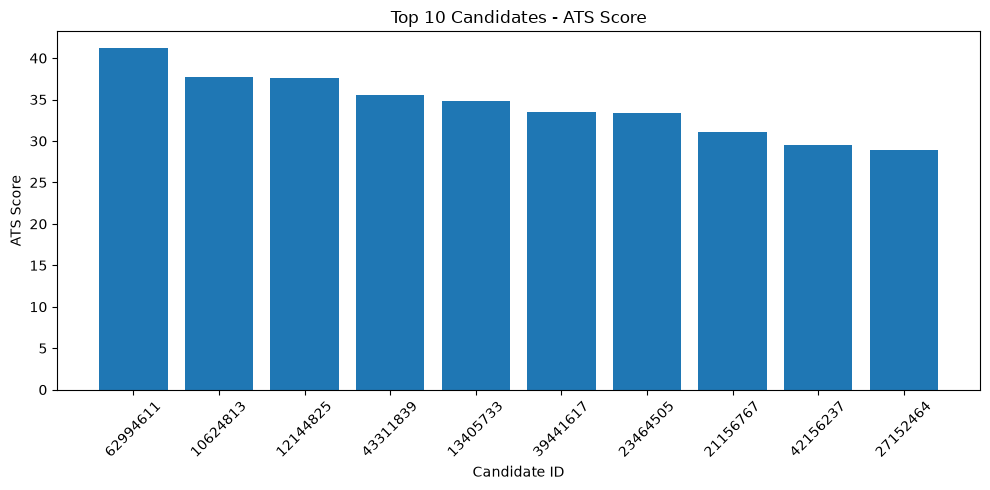

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    shortlisted["ID"].astype(str),
    shortlisted["ATS_Score"]
)

plt.xlabel("Candidate ID")
plt.ylabel("ATS Score")
plt.title("Top 10 Candidates - ATS Score")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
df.to_csv("processed_resume_dataset.csv", index=False)

print("Processed dataset saved successfully!")f

SyntaxError: invalid syntax (1261707242.py, line 3)

In [19]:
df.to_csv("processed_resume_dataset.csv", index=False)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [20]:
ranking_df.to_csv("candidate_ranking.csv", index=False)

print("Candidate ranking saved successfully!")

Candidate ranking saved successfully!


In [21]:
import os

files = [
    "resume_model.pkl",
    "tfidf_vectorizer.pkl",
    "required_skills.pkl",
    "shortlisted_candidates.csv",
    "candidate_ranking.csv",
    "processed_resume_dataset.csv"
]

for file in files:
    print(file, "✅" if os.path.exists(file) else "❌")

resume_model.pkl ✅
tfidf_vectorizer.pkl ✅
required_skills.pkl ✅
shortlisted_candidates.csv ✅
candidate_ranking.csv ✅
processed_resume_dataset.csv ✅


In [22]:
sample_resume = """
Python developer with experience in Django, Flask, SQL,
REST API, Git, data structures and software development.
"""

sample_clean = remove_stopwords(clean_text(sample_resume))
sample_vector = tfidf.transform([sample_clean])

prediction = model.predict(sample_vector)

print("Predicted Category:", prediction[0])

Predicted Category: ENGINEERING


In [23]:
similarity = cosine_similarity(
    job_vector,
    sample_vector
)[0][0] * 100

matched_skills = [
    skill for skill in required_skills
    if skill.lower() in sample_clean
]

skill_score = (
    len(matched_skills) / len(required_skills)
) * 100

ats_score = (similarity * 0.4) + (skill_score * 0.6)

if ats_score >= 70:
    recommendation = "Strong Match"
elif ats_score >= 50:
    recommendation = "Good Match"
elif ats_score >= 30:
    recommendation = "Moderate Match"
else:
    recommendation = "Low Match"

print("Predicted Category:", prediction[0])
print("Similarity:", round(similarity, 2), "%")
print("Skill Score:", round(skill_score, 2), "%")
print("ATS Score:", round(ats_score, 2), "%")
print("Matched Skills:", matched_skills)
print("Recommendation:", recommendation)

Predicted Category: ENGINEERING
Similarity: 90.52 %
Skill Score: 100.0 %
ATS Score: 96.21 %
Matched Skills: ['python', 'django', 'flask', 'sql', 'rest api', 'git', 'data structures', 'software development']
Recommendation: Strong Match


In [24]:
test_result = {
    "Predicted_Category": prediction[0],
    "Similarity": round(similarity, 2),
    "Skill_Score": round(skill_score, 2),
    "ATS_Score": round(ats_score, 2),
    "Matched_Skills": ", ".join(matched_skills),
    "Recommendation": recommendation
}

pd.DataFrame([test_result]).to_csv(
    "sample_resume_ats_result.csv",
    index=False
)

print("ATS test result saved successfully!")

ATS test result saved successfully!
